# Medical Insurance Cost Prediction

## Project Objective

The objective of this project is to predict medical insurance charges based on personal characteristics such as age, BMI, number of children, smoking status, and other available features.

A Linear Regression model is used to understand the relationship between these features and medical insurance costs.

## Importing Libraries

Import the required libraries for data manipulation, numerical operations, data visualization, and Machine Learning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the Dataset

Load the medical insurance dataset into a Pandas DataFrame for analysis.

In [2]:
df=pd.read_csv('insurance.csv')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
df.shape

(1338, 7)

In [6]:
df.isnull().sum()


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
df.duplicated().sum()

1

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.duplicated().sum()

0

In [10]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Exploratory Data Analysis (EDA)

Explore the dataset using statistical summaries and visualizations to understand the distribution of insurance charges and the relationships between different features.

<Axes: xlabel='charges', ylabel='Count'>

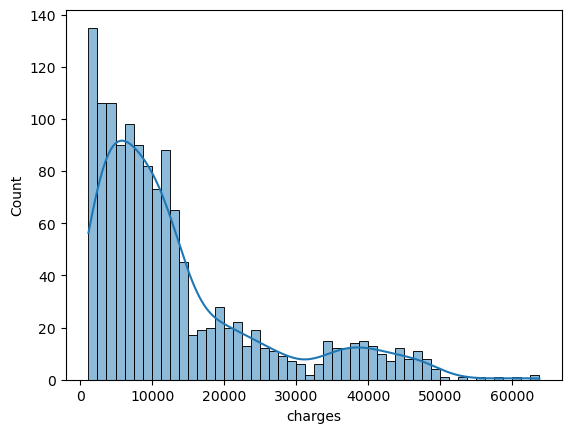

In [11]:
sns.histplot(data=df,x='charges',kde=True,bins=50)

In [12]:
df.select_dtypes(include='object').columns

Index(['sex', 'smoker', 'region'], dtype='object')

In [13]:
df['sex'].value_counts()

male      675
female    662
Name: sex, dtype: int64

In [14]:
df['smoker'].value_counts()

no     1063
yes     274
Name: smoker, dtype: int64

In [15]:
df['region'].value_counts()

southeast    364
southwest    325
northwest    324
northeast    324
Name: region, dtype: int64

In [16]:
corr=df.corr(numeric_only=True)
print(corr)

               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


<Axes: >

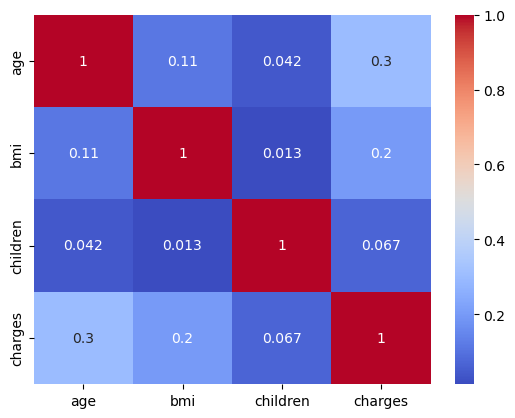

In [17]:
sns.heatmap(corr,annot=True,cmap="coolwarm")

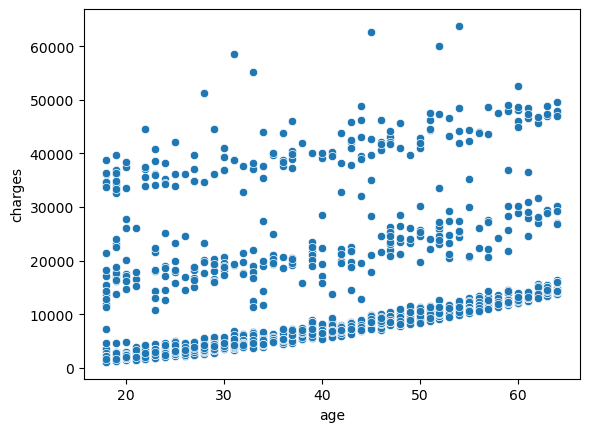

In [18]:
sns.scatterplot(x='age', y='charges', data=df)
plt.show()

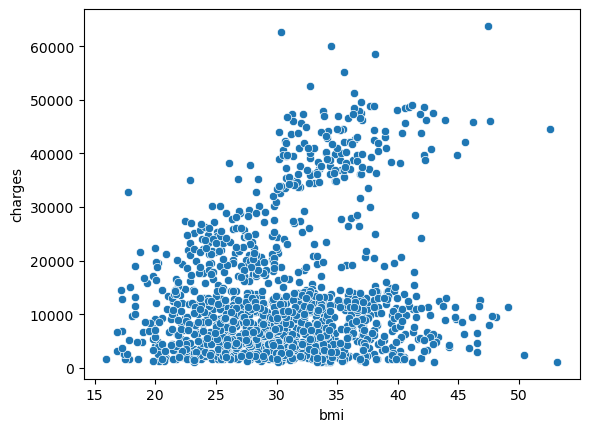

In [19]:
sns.scatterplot(x='bmi', y='charges', data=df)
plt.show()

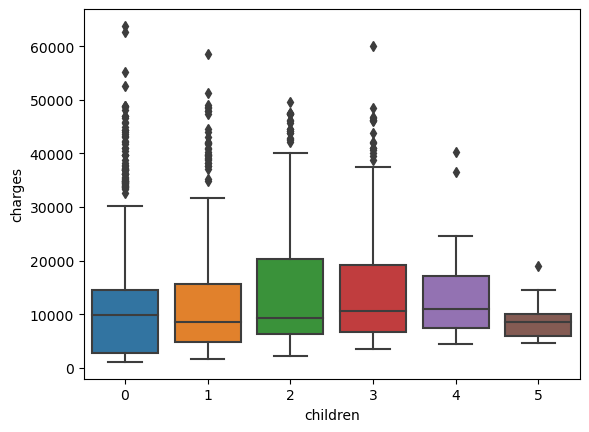

In [20]:
sns.boxplot(x='children', y='charges', data=df)
plt.show()

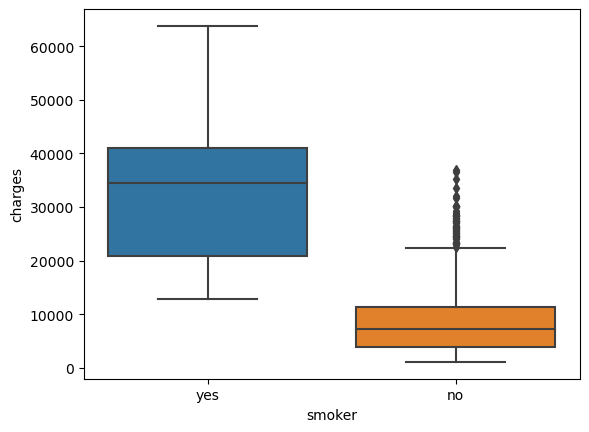

In [21]:
sns.boxplot(x='smoker', y='charges', data=df)
plt.show()

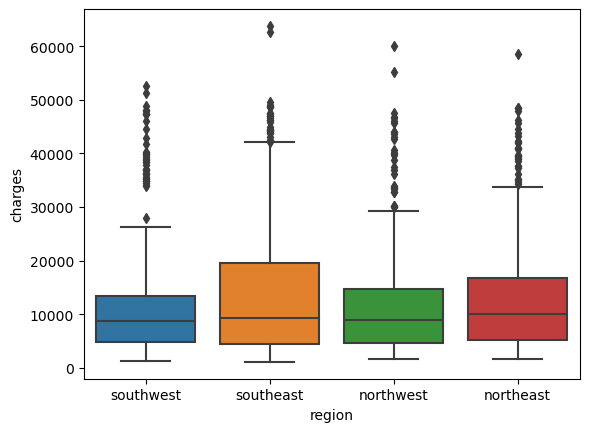

In [22]:
sns.boxplot(x='region', y='charges', data=df)
plt.show()

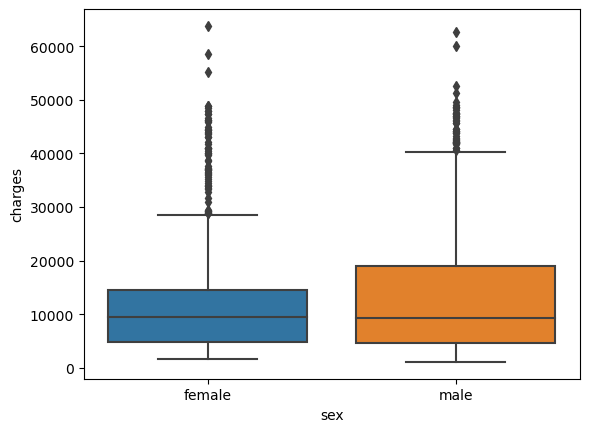

In [23]:
sns.boxplot(x='sex', y='charges', data=df)
plt.show()

## Data Preprocessing

Prepare the dataset for Machine Learning by separating the input features from the target variable and encoding categorical features into numerical values.

In [24]:
X = df.drop('charges', axis=1)
y = df['charges']

In [25]:
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [26]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [27]:
X = df.drop('charges', axis=1)
y = df['charges']

X = pd.get_dummies(X, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)

X['age_smoker'] = X['age'] * X['smoker_yes']

x = X.copy()

In [28]:
X.shape

(1337, 9)

In [29]:
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,age_smoker
0,19,27.900,0,0,1,0,0,1,19
1,18,33.770,1,1,0,0,1,0,0
2,28,33.000,3,1,0,0,1,0,0
3,33,22.705,0,1,0,1,0,0,0
4,32,28.880,0,1,0,1,0,0,0


In [30]:
x.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,age_smoker
0,19,27.900,0,0,1,0,0,1,19
1,18,33.770,1,1,0,0,1,0,0
2,28,33.000,3,1,0,0,1,0,0
3,33,22.705,0,1,0,1,0,0,0
4,32,28.880,0,1,0,1,0,0,0


## Train-Test Split

Split the dataset into training and testing sets. The training set is used to train the model, while the testing set is used to evaluate its performance on unseen data.

In [31]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

## Model Building and Prediction

Train a Linear Regression model using the training data and use it to predict medical insurance charges for the testing data.

In [32]:
from sklearn.linear_model import LinearRegression 


In [33]:
model=LinearRegression()

In [34]:
model.fit(x_train,y_train)

LinearRegression()

In [35]:
y_pred=model.predict(x_test)

In [36]:
from sklearn.metrics import mean_squared_error,r2_score

## Model Evaluation

Evaluate the model using regression metrics such as R² score and Root Mean Squared Error (RMSE) to understand how well it predicts medical insurance charges.

In [37]:
mse_test=mean_squared_error(y_test,y_pred)
print(mse_test)

35282682.39041191


In [38]:
r2_test=r2_score(y_test,y_pred)
print(r2_test)

0.8079917385337526


In [39]:
rmse_test=np.sqrt(mse_test)
mean_y=np.mean(y_test)
print(rmse_test)
print(mean_y)

5939.922759633489
14272.007559287313


In [40]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
900,8688.85885,8093.154031
1064,5708.86700,5781.031329
1256,11436.73815,14308.379847
298,38746.35510,31598.397258
237,4463.20510,8991.921412
481,9304.70190,13091.391866
240,38511.62830,30170.825014
277,2150.46900,1553.415654
415,7345.72660,10614.652120
707,10264.44210,11251.046812


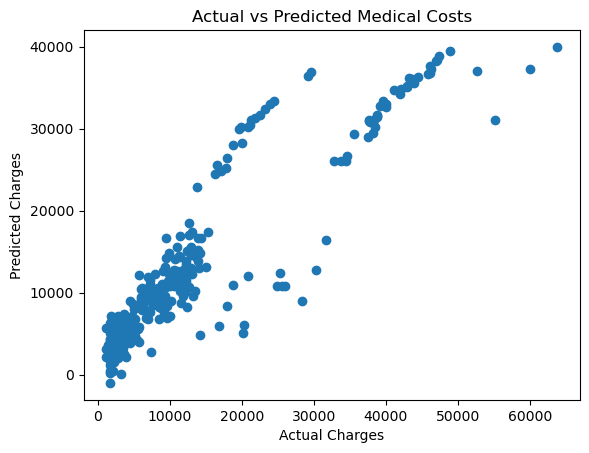

In [41]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Medical Costs')
plt.show()

## Conclusion

A Linear Regression model was developed to predict medical insurance charges. The model's performance was evaluated using regression metrics to understand its predictive accuracy and identify opportunities for further improvement.